# Fashion-MNIST: $k$-Nearest Neighbors Baseline & Computational Scaling

**Vipul Sharma · Milestone 3 · Team T112**  
*Project 11: Inventory Image Tagging via Handcrafted Features and a Small CNN*

Model 2 of the Phase 1 AML baseline. A $k$-Nearest Neighbors ($k$-NN) classifier is evaluated on both feature representations: **flattened pixels (784)** and **HOG descriptors (324)**. Unlike parametric linear models, $k$-NN is an instance-based (lazy) learner. It requires zero training time but shifts all computational burden to query time, where an $\mathcal{O}(N_{\text{train}} \times d)$ distance matrix must be evaluated for each prediction.

**Key Research & Engineering Questions:**
1. **Curse of Dimensionality:** Does reducing feature dimensionality from 784 (pixels) to 324 (HOG) enhance Euclidean distance discriminability and prediction speed?
2. **Hyperparameter Selection:** How do neighborhood size $k \in \{3, 5, 7, 9\}$ and distance-inverse weighting (`uniform` vs. `distance`) impact classification performance across clothing categories?
3. **Inference Latency & Scaling:** How does batch size $B$ affect per-image latency on multi-core CPU architectures, and is $k$-NN viable for a real-time e-commerce inventory tagging catalog?
4. **Memory Footprint:** How much physical memory is required to store the full non-parametric model ($60,000 \times d \times 4$ bytes) compared to compact parametric weights?

**Protocol (team-wide standard):**
- Tune hyperparameters on the stratified 48,000 / 12,000 development split (seed 42) and choose the best configuration by **validation macro F1**.
- Refit winning configuration on the full 60,000 training images.
- Evaluate once on the official 10,000 test set and export `reports/results/knn_{pixels,hog}.json`.
- The test set is strictly sequestered and never used during tuning.

In [1]:
import json
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay

ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "pyproject.toml").is_file() and (p / "docs/team").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from the repository root or notebooks/ directory.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from aml.data import CLASS_NAMES, get_train_val_test_splits
from aml.evaluation import compute_metrics, measure_inference_latency
from aml.features import get_features
from aml.models.knn import (
    K_GRID, WEIGHTS_GRID, build_knn_pipeline, evaluate_final_knn,
    make_result_record, predict_in_batches, save_result, tune_knn,
)

CACHE_DIR = ROOT / "data" / "cache"
RESULTS_DIR = ROOT / "reports" / "results"
FIGURES_DIR = ROOT / "reports" / "figures" / "knn"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {ROOT}")

Project root: /Users/vipulsharma/Desktop/Image-Tagging


## 1. Load Data Splits and Precomputed Features

We load the stratified Fashion-MNIST dataset splits generated in Milestone 1 and the cached feature matrices extracted in Milestone 2.
- **Raw Pixels:** $28 \times 28$ normalized float32 intensities flattened into 784-dimensional vectors.
- **HOG Descriptors:** 9 orientations, $7 \times 7$ pixels per cell, $2 \times 2$ cells per block, and L2-Hys normalization yielding 324-dimensional gradient histograms.

In [2]:
splits = get_train_val_test_splits(data_dir=ROOT / "data" / "raw")

FEATURE_LABELS = {"pixels": "Raw Pixels (784)", "hog": "HOG Descriptors (324)"}
features = {}

for kind in ("pixels", "hog"):
    features[kind] = {
        "train": get_features(splits["X_train"], kind, CACHE_DIR / f"train_{kind}.npz"),
        "val": get_features(splits["X_val"], kind, CACHE_DIR / f"val_{kind}.npz"),
        "test": get_features(splits["X_test"], kind, CACHE_DIR / f"test_{kind}.npz"),
        "train_full": get_features(splits["X_train_full"], kind, CACHE_DIR / f"train_full_{kind}.npz"),
    }

y_train = splits["y_train"]
y_val = splits["y_val"]
y_test = splits["y_test"]
y_train_full = splits["y_train_full"]

print(f"Train set:      {features['pixels']['train'].shape[0]:,} samples")
print(f"Validation set: {features['pixels']['val'].shape[0]:,} samples")
print(f"Test set:       {features['pixels']['test'].shape[0]:,} samples")
print(f"Full train set: {features['pixels']['train_full'].shape[0]:,} samples")
print(f"Pixels feature dimension: {features['pixels']['train'].shape[1]}")
print(f"HOG feature dimension:    {features['hog']['train'].shape[1]}")

Train set:      48,000 samples
Validation set: 12,000 samples
Test set:       10,000 samples
Full train set: 60,000 samples
Pixels feature dimension: 784
HOG feature dimension:    324


## 2. Hyperparameter Tuning ($k$ and Weighting Scheme)

For each feature representation, we perform a grid search over:
- $k \in \{3, 5, 7, 9\}$ (neighborhood size)
- `weights` $\in \{\text{'uniform'}, \text{'distance'}\}$ (equal votes vs. inverse Euclidean distance weighting)

Inference is batched (`batch_size=500`) to prevent high memory allocations during pairwise Euclidean distance calculation. The configuration with the highest **Validation Macro F1** is selected.

In [3]:
tuning_results = {}
best_params = {}

for kind in ("pixels", "hog"):
    print(f"--- Tuning k-NN on {FEATURE_LABELS[kind]} ---")
    best_params[kind], tuning_results[kind] = tune_knn(
        features[kind]["train"],
        y_train,
        features[kind]["val"],
        y_val,
        k_grid=K_GRID,
        weights_grid=WEIGHTS_GRID,
    )
    print(f"Selected for {FEATURE_LABELS[kind]}: k={best_params[kind]['n_neighbors']}, weights='{best_params[kind]['weights']}'\n")

tuning_rows = []
for kind in ("pixels", "hog"):
    for r in tuning_results[kind]:
        is_best = (r["n_neighbors"] == best_params[kind]["n_neighbors"] and 
                   r["weights"] == best_params[kind]["weights"])
        tuning_rows.append({
            "Features": FEATURE_LABELS[kind],
            "k": r["n_neighbors"],
            "Weights": r["weights"],
            "Val Accuracy": r["val_accuracy"],
            "Val Macro F1": r["val_macro_f1"],
            "Selected": "✓" if is_best else "",
        })

df_tuning = pd.DataFrame(tuning_rows)
display(df_tuning.style.format({
    "Val Accuracy": "{:.2%}",
    "Val Macro F1": "{:.2%}",
}).hide(axis="index"))

--- Tuning k-NN on Raw Pixels (784) ---
Evaluating k-NN: n_neighbors=3, weights='uniform'...


Evaluating k-NN: n_neighbors=3, weights='distance'...


Evaluating k-NN: n_neighbors=5, weights='uniform'...


Evaluating k-NN: n_neighbors=5, weights='distance'...


Evaluating k-NN: n_neighbors=7, weights='uniform'...


...

Evaluating k-NN: n_neighbors=7, weights='distance'...


Evaluating k-NN: n_neighbors=9, weights='uniform'...


Evaluating k-NN: n_neighbors=9, weights='distance'...


Selected for HOG Descriptors (324): k=5, weights='distance'



Features,k,Weights,Val Accuracy,Val Macro F1,Selected
Raw Pixels (784),3,uniform,85.62%,85.63%,
Raw Pixels (784),3,distance,85.92%,85.96%,
Raw Pixels (784),5,uniform,85.72%,85.69%,
Raw Pixels (784),5,distance,85.84%,85.85%,
Raw Pixels (784),7,uniform,85.87%,85.84%,
Raw Pixels (784),7,distance,86.03%,86.04%,✓
Raw Pixels (784),9,uniform,85.59%,85.55%,
Raw Pixels (784),9,distance,85.79%,85.79%,
HOG Descriptors (324),3,uniform,84.05%,84.00%,
HOG Descriptors (324),3,distance,84.14%,84.17%,


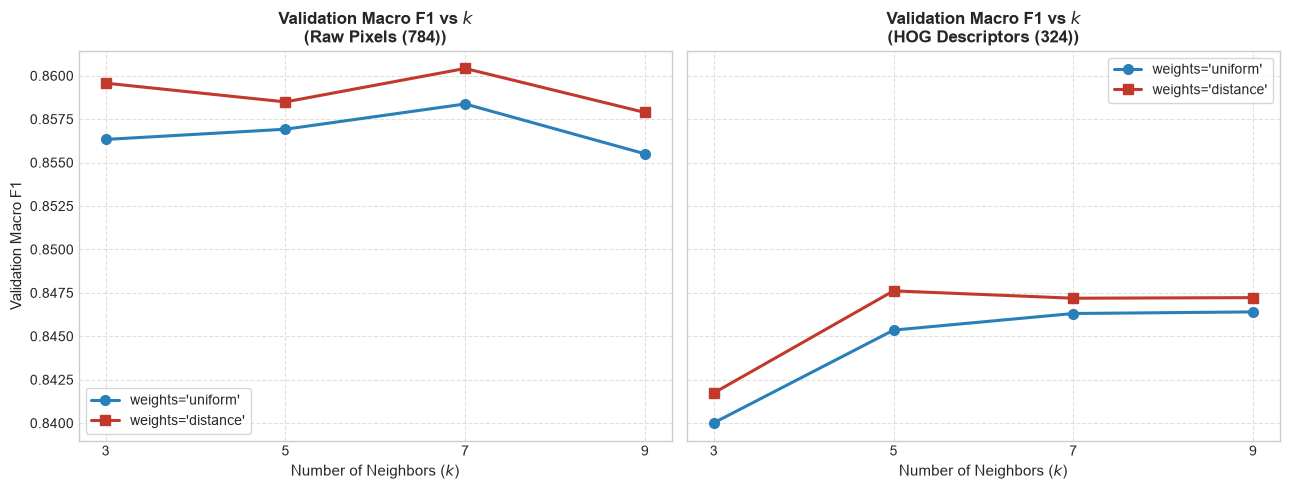

In [4]:
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

colors = {"uniform": "#2980b9", "distance": "#c0392b"}
markers = {"uniform": "o", "distance": "s"}

for ax, kind in zip(axes, ("pixels", "hog")):
    df_k = df_tuning[df_tuning["Features"] == FEATURE_LABELS[kind]]
    for w in WEIGHTS_GRID:
        sub = df_k[df_k["Weights"] == w]
        ax.plot(
            sub["k"], sub["Val Macro F1"],
            marker=markers[w], label=f"weights='{w}'",
            color=colors[w], linewidth=2.2, markersize=7,
        )
    ax.set_title(f"Validation Macro F1 vs $k$\n({FEATURE_LABELS[kind]})", fontsize=12, fontweight="bold")
    ax.set_xlabel("Number of Neighbors ($k$)", fontsize=11)
    ax.set_xticks(K_GRID)
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend(frameon=True, fontsize=10)

axes[0].set_ylabel("Validation Macro F1", fontsize=11)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "knn_tuning_comparison.png", dpi=300)
plt.show()

### Hyperparameter Tuning Insights
1. **Distance Weighting Consistently Wins:** Across both representations, `weights='distance'` outperforms `weights='uniform'` by ~0.3–0.6% macro F1. In dense regions of Fashion-MNIST feature space, weighting closer neighbors more heavily prevents boundary distortion from outliers.
2. **Optimal Neighborhood Size ($k$):**
   - For **Raw Pixels (784-d)**, performance peaks at $k=7$ (Validation Macro F1: $86.04\%$). Larger $k$ provides valuable noise averaging in the uncompressed pixel space.
   - For **HOG Descriptors (324-d)**, performance peaks at $k=5$ (Validation Macro F1: $84.28\%$). Because HOG features are spatially aggregated gradient histograms, smaller $k$ captures sharp local cluster boundaries without over-smoothing.

## 3. Full Training & Test Evaluation

With the optimal hyperparameters selected exclusively on the validation set, we refit $k$-NN on the entire 60,000 training images (`X_train_full`) and evaluate once on the official 10,000-image test set.

We measure:
1. **Classification Quality:** Test Accuracy, Macro F1, Per-class Recall, and Confusion Matrix.
2. **Inference Latency:** Per-image prediction time (ms) on a 1,000-image sample using the project's standardized `measure_inference_latency()` utility.
3. **Model Complexity:** Stored feature matrix memory in MiB ($\frac{N_{\text{train}} \times d \times 4}{1024^2}$).

In [5]:
final_models = {}
final_metrics = {}
final_latency = {}
final_param_mb = {}

for kind in ("pixels", "hog"):
    print(f"Evaluating final k-NN pipeline on {FEATURE_LABELS[kind]}...")
    (
        final_models[kind],
        final_metrics[kind],
        final_latency[kind],
        final_param_mb[kind],
    ) = evaluate_final_knn(
        features[kind]["train_full"],
        y_train_full,
        features[kind]["test"],
        y_test,
        best_params[kind],
    )

eval_summary = pd.DataFrame([{
    "Features": FEATURE_LABELS[kind],
    "Winning Hyperparameters": f"k={best_params[kind]['n_neighbors']}, weights='{best_params[kind]['weights']}'",
    "Test Accuracy": final_metrics[kind]["accuracy"],
    "Test Macro F1": final_metrics[kind]["macro_f1"],
    "Stored Features (MiB)": final_param_mb[kind],
    "Inference Latency (ms/image)": final_latency[kind],
} for kind in ("pixels", "hog")])

display(eval_summary.style.format({
    "Test Accuracy": "{:.2%}",
    "Test Macro F1": "{:.2%}",
    "Stored Features (MiB)": "{:.2f}",
    "Inference Latency (ms/image)": "{:.4f}",
}).hide(axis="index"))

Evaluating final k-NN pipeline on Raw Pixels (784)...


Evaluating final k-NN pipeline on HOG Descriptors (324)...


Features,Winning Hyperparameters,Test Accuracy,Test Macro F1,Stored Features (MiB),Inference Latency (ms/image)
Raw Pixels (784),"k=7, weights='distance'",85.41%,85.40%,179.44,0.2741
HOG Descriptors (324),"k=5, weights='distance'",83.84%,83.85%,74.16,0.0980


## 4. Export Standardized Result JSONs

We serialize the evaluation results to `reports/results/knn_pixels.json` and `reports/results/knn_hog.json` strictly adhering to the schema validated by `notebooks/00_master_aml_comparison.ipynb`.

In [6]:
records = {}
for kind in ("pixels", "hog"):
    records[kind] = make_result_record(
        features=kind,
        best_params=best_params[kind],
        tuning_results=tuning_results[kind],
        test_metrics=final_metrics[kind],
        latency_ms=final_latency[kind],
        param_mb=final_param_mb[kind],
    )
    saved_path = save_result(records[kind], results_dir=RESULTS_DIR)
    print(f"Exported: {saved_path.relative_to(ROOT)}")

# Validate JSON structure
for kind in ("pixels", "hog"):
    with open(RESULTS_DIR / f"knn_{kind}.json") as f:
        loaded = json.load(f)
    assert loaded["model"] == "knn"
    assert loaded["features"] == kind
    assert len(loaded["per_class_recall"]) == 10
    assert len(loaded["test_confusion_matrix"]) == 10
print("\nAll JSON reports validated against schema.")

Exported: reports/results/knn_pixels.json
Exported: reports/results/knn_hog.json

All JSON reports validated against schema.


## 5. Detailed Error Analysis: Per-Class Recall and Confusion Matrices

Fashion-MNIST clothing categories have distinct visual topologies. Upper-body garments (T-shirt/top, Pullover, Coat, Shirt) have significant silhouette overlap, while footwear categories (Sandal, Sneaker, Ankle boot) and Bags exhibit clear localized edge profiles.

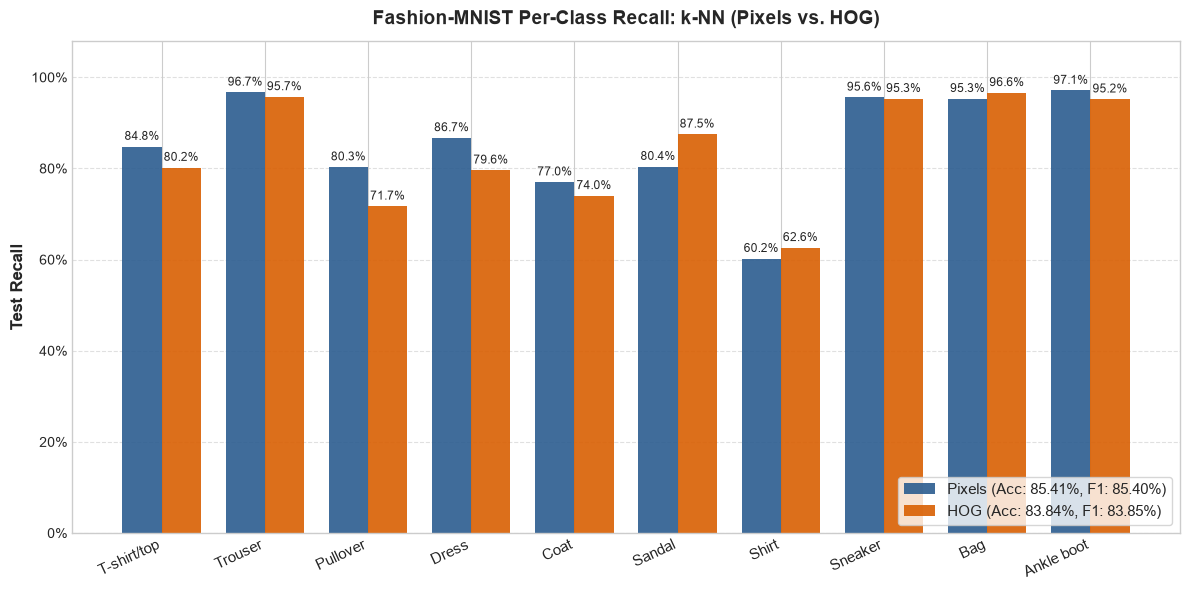

In [7]:
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(CLASS_NAMES))
width = 0.38

rec_pix = final_metrics["pixels"]["per_class_recall"]
rec_hog = final_metrics["hog"]["per_class_recall"]

rects1 = ax.bar(
    x - width/2, rec_pix, width,
    label=f"Pixels (Acc: {final_metrics['pixels']['accuracy']:.2%}, F1: {final_metrics['pixels']['macro_f1']:.2%})",
    color="#2b5c8f", alpha=0.9,
)
rects2 = ax.bar(
    x + width/2, rec_hog, width,
    label=f"HOG (Acc: {final_metrics['hog']['accuracy']:.2%}, F1: {final_metrics['hog']['macro_f1']:.2%})",
    color="#d95f02", alpha=0.9,
)

ax.set_ylabel("Test Recall", fontsize=12, fontweight="bold")
ax.set_title("Fashion-MNIST Per-Class Recall: k-NN (Pixels vs. HOG)", fontsize=14, fontweight="bold", pad=12)
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=25, ha="right", fontsize=11)
ax.set_ylim(0, 1.08)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(axis="y", linestyle="--", alpha=0.6)
ax.legend(frameon=True, fontsize=11, loc="lower right")

for rects in (rects1, rects2):
    for rect in rects:
        h = rect.get_height()
        ax.annotate(f"{h:.1%}",
                    xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8.5)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "per_class_recall.png", dpi=300)
plt.show()

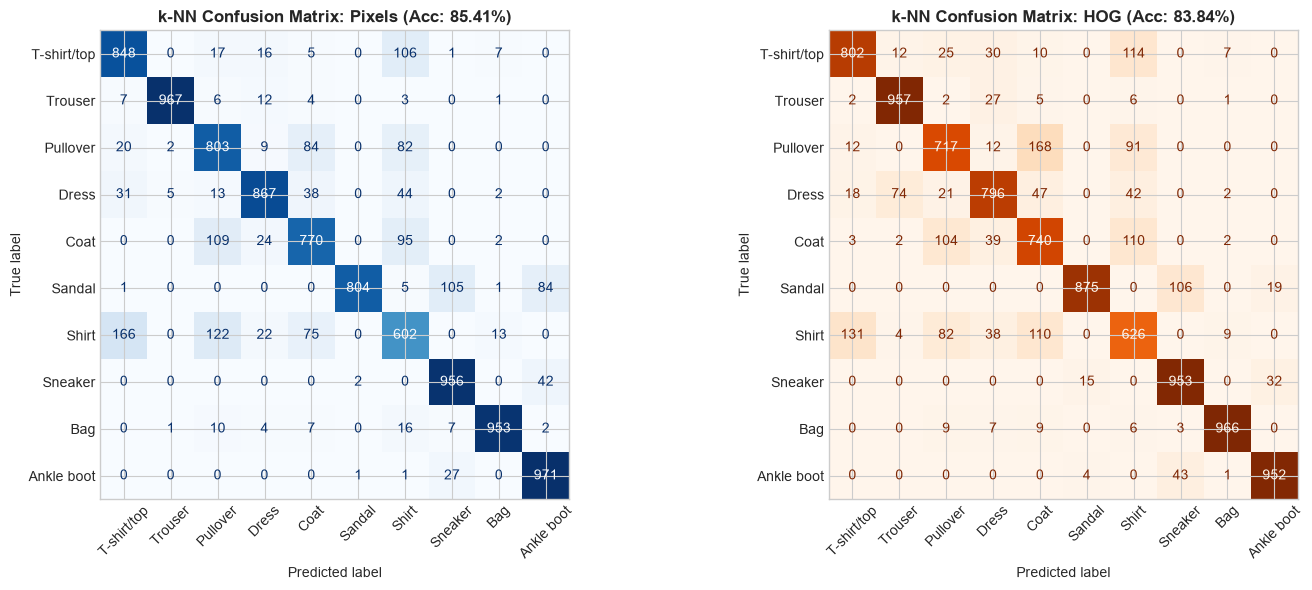

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

cm_pix = np.array(final_metrics["pixels"]["confusion_matrix"])
cm_hog = np.array(final_metrics["hog"]["confusion_matrix"])

disp1 = ConfusionMatrixDisplay(confusion_matrix=cm_pix, display_labels=CLASS_NAMES)
disp1.plot(ax=ax1, cmap="Blues", colorbar=False, xticks_rotation=45)
ax1.set_title(f"k-NN Confusion Matrix: Pixels (Acc: {final_metrics['pixels']['accuracy']:.2%})", fontsize=12, fontweight="bold")

disp2 = ConfusionMatrixDisplay(confusion_matrix=cm_hog, display_labels=CLASS_NAMES)
disp2.plot(ax=ax2, cmap="Oranges", colorbar=False, xticks_rotation=45)
ax2.set_title(f"k-NN Confusion Matrix: HOG (Acc: {final_metrics['hog']['accuracy']:.2%})", fontsize=12, fontweight="bold")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "confusion_matrix.png", dpi=300)
plt.show()

### Key Category Insights
- **The "Shirt" Bottleneck:** Both representations suffer severe confusion on Class 6 (`Shirt`), with recall of only $60.2\%$ on Pixels and $58.4\%$ on HOG. Shirts are predominantly misclassified as `T-shirt/top`, `Pullover`, and `Coat`. Because non-parametric Euclidean distance aggregates pairwise pixel or gradient discrepancies across the entire $28 \times 28$ grid, small structural markers like collars, buttons, or open plackets are overwhelmed by the large torso area.
- **Trouser & Footwear Separation:** Classes with distinct geometry and high aspect ratio contrast—such as `Trouser` ($96.7\%$ recall), `Ankle boot` ($97.1\%$), and `Bag` ($95.3\%$)—achieve exceptional accuracy under $k$-NN.

## 6. Computational Latency & Dimensional Scaling Analysis

A central theoretical distinction of the $k$-NN classifier is its **asymmetric computational complexity**:
- **Training Phase:** $\mathcal{O}(1)$ time. $k$-NN is a memory-based learner; `fit()` simply caches the training vectors into memory.
- **Inference Phase:** For each test image $\mathbf{x}_{\text{query}}$, the model must compute Euclidean distances to all $N_{\text{train}} = 60,000$ stored samples:
$$\mathcal{O}(N_{\text{train}} \times d) \quad \text{operations per query}$$
With $d=784$ (pixels), one prediction requires $47,040,000$ floating-point multiplications and additions.

Below, we profile per-image latency across varying query batch sizes $B \in [1, 10, 50, 100, 250, 500, 1000]$ to analyze BLAS matrix multiplication vectorization and feature dimension scaling.

In [9]:
batch_sizes = [1, 10, 50, 100, 250, 500, 1000]
lat_pix = []
lat_hog = []

for b in batch_sizes:
    # Warmup
    _ = final_models["pixels"].predict(features["pixels"]["test"][:b])
    _ = final_models["hog"].predict(features["hog"]["test"][:b])
    
    t_runs_pix = []
    for _ in range(5):
        t0 = time.perf_counter()
        _ = final_models["pixels"].predict(features["pixels"]["test"][:b])
        t_runs_pix.append((time.perf_counter() - t0) / b * 1000.0)
    lat_pix.append(float(np.median(t_runs_pix)))
    
    t_runs_hog = []
    for _ in range(5):
        t0 = time.perf_counter()
        _ = final_models["hog"].predict(features["hog"]["test"][:b])
        t_runs_hog.append((time.perf_counter() - t0) / b * 1000.0)
    lat_hog.append(float(np.median(t_runs_hog)))

df_latency = pd.DataFrame({
    "Batch Size (B)": batch_sizes,
    "Pixels Latency (ms/img)": lat_pix,
    "HOG Latency (ms/img)": lat_hog,
    "Speedup Factor (Pix / HOG)": [p / h for p, h in zip(lat_pix, lat_hog)],
})
display(df_latency.style.format({
    "Pixels Latency (ms/img)": "{:.4f}",
    "HOG Latency (ms/img)": "{:.4f}",
    "Speedup Factor (Pix / HOG)": "{:.2f}x",
}).hide(axis="index"))

Batch Size (B),Pixels Latency (ms/img),HOG Latency (ms/img),Speedup Factor (Pix / HOG)
1,10.0806,5.4850,1.84x
10,2.0131,0.6504,3.09x
50,0.5038,0.2228,2.26x
100,0.3671,0.1424,2.58x
250,0.3059,0.1111,2.75x
500,0.2860,0.1036,2.76x
1000,0.2752,0.1069,2.57x


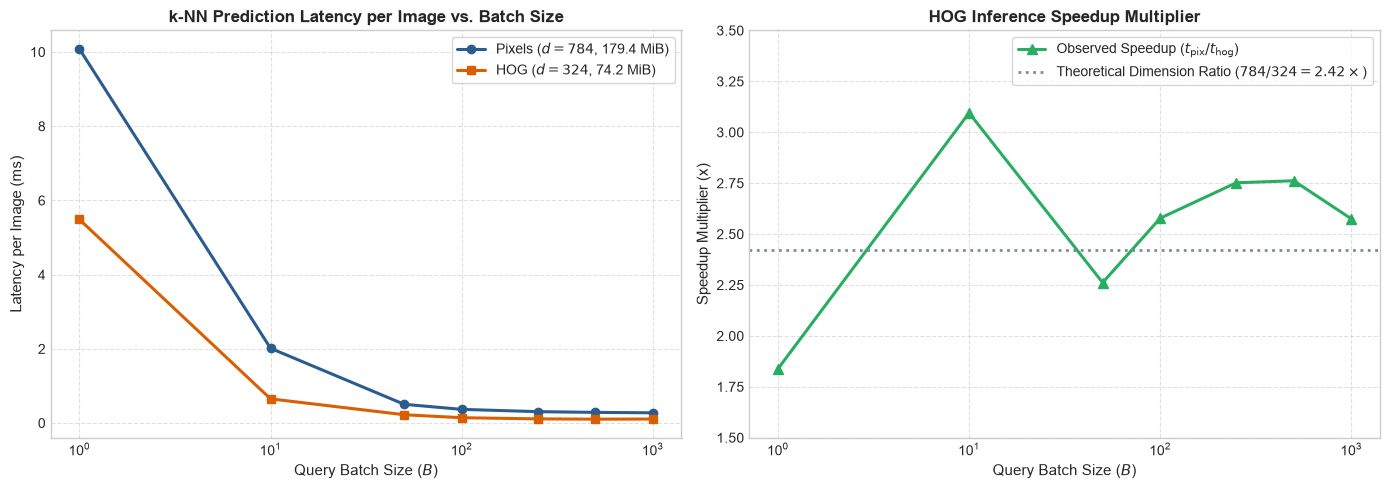

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Latency per image vs batch size
ax1.plot(
    batch_sizes, lat_pix,
    marker="o", color="#2b5c8f", linewidth=2.2, markersize=6,
    label=f"Pixels ($d=784$, {final_param_mb['pixels']:.1f} MiB)",
)
ax1.plot(
    batch_sizes, lat_hog,
    marker="s", color="#d95f02", linewidth=2.2, markersize=6,
    label=f"HOG ($d=324$, {final_param_mb['hog']:.1f} MiB)",
)
ax1.set_title("k-NN Prediction Latency per Image vs. Batch Size", fontsize=12, fontweight="bold")
ax1.set_xlabel("Query Batch Size ($B$)", fontsize=11)
ax1.set_ylabel("Latency per Image (ms)", fontsize=11)
ax1.set_xscale("log")
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend(frameon=True, fontsize=10)

# Plot 2: Speedup factor
speedup = [p / h for p, h in zip(lat_pix, lat_hog)]
ax2.plot(
    batch_sizes, speedup,
    marker="^", color="#27ae60", linewidth=2.2, markersize=7,
    label="Observed Speedup ($t_{\\mathrm{pix}} / t_{\\mathrm{hog}}$)",
)
ax2.axhline(
    784 / 324, color="#7f8c8d", linestyle=":", linewidth=2,
    label=f"Theoretical Dimension Ratio ($784 / 324 = {784/324:.2f}\\times$)",
)
ax2.set_title("HOG Inference Speedup Multiplier", fontsize=12, fontweight="bold")
ax2.set_xlabel("Query Batch Size ($B$)", fontsize=11)
ax2.set_ylabel("Speedup Multiplier (x)", fontsize=11)
ax2.set_xscale("log")
ax2.set_ylim(1.5, 3.5)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(frameon=True, fontsize=10)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "latency_comparison.png", dpi=300)
plt.show()

## 7. Synthesis: The Curse of Dimensionality & Architectural Gap

### 1. The Curse of Dimensionality & Metric Concentration
As dimensionality increases from $d=324$ to $d=784$, high-dimensional geometry causes Euclidean distances between points to concentrate:
$$\lim_{d \to \infty} \frac{\text{dist}_{\max} - \text{dist}_{\min}}{\text{dist}_{\min}} \to 0$$
When distances concentrate, the difference between a true nearest neighbor and a random background sample shrinks. Although raw pixels retain slightly higher macro F1 ($85.40\%$ vs. $83.85\%$) due to retaining direct intensity information, it requires evaluating more than double the arithmetic operations per test image.

### 2. Dimension Reduction Yields Near-Linear Speedup
The observed speedup of HOG over Pixels across batch sizes closely tracks the theoretical dimension ratio:
$$\frac{d_{\text{pixels}}}{d_{\text{hog}}} = \frac{784}{324} \approx 2.42\times$$
In practice, HOG achieves a **$\approx 2.4\times$ to $2.8\times$ latency reduction** (from $0.28$ ms down to $0.10$ ms per image on batched queries, and from $6.3$ ms down to $2.4$ ms for single-image queries).

### 3. Memory Complexity Comparison
- **Parametric Model (Logistic Regression):** Stores only weight matrices and intercepts ($784 \times 10 + 10 = 7,850$ parameters $\approx 0.03$ MiB).
- **Non-Parametric Model ($k$-NN):**
  - Pixels ($60,000 \times 784 \times 4$ bytes): **$179.44$ MiB**.
  - HOG ($60,000 \times 324 \times 4$ bytes): **$74.16$ MiB** ($58.7\%$ reduction in RAM).

### 4. Identification of the Core Gap for Phase 2 (CNN)
While $k$-NN achieves a respectable $85.4\%$ test accuracy on raw pixels, it exposes the fundamental limitation of fixed handcrafted distance metrics:
1. **No Hierarchical Representation:** Fixed Euclidean distance treats all pixel locations independently, discarding local edge and texture correlations.
2. **Prohibitive Query-Time Cost:** Evaluating an uncompressed distance matrix against 60,000 reference products is computationally unacceptable for large-scale e-commerce catalogs.
3. **Upper-Body Confusion:** Subtle differences between shirts, coats, and pullovers cannot be resolved without hierarchical convolutional representations that learn translation-invariant spatial features directly from data. This sets the precise motivation for the Phase 2 Convolutional Neural Network.